In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("diabetes_prediction_dataset.csv")

print("First 5 Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

First 5 Records:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  

Dataset Shape:
(27528, 9)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 27528 entries, 0 to 27527
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender           

In [3]:
X = df.drop('diabetes', axis=1)

print("Features:")
print(X.head())

print("\nFeatures Shape:", X.shape)

Features:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  
0          6.6                  140  
1          6.6                   80  
2          5.7                  158  
3          5.0                  155  
4          4.8                  155  

Features Shape: (27528, 8)


In [4]:
categorical_columns = ['gender', 'smoking_history']

numerical_columns = [
    'age',
    'hypertension',
    'heart_disease',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level'
]

print("Categorical Columns:", categorical_columns)
print("Numerical Columns:", numerical_columns)

Categorical Columns: ['gender', 'smoking_history']
Numerical Columns: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']


In [5]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
    ]
)

X_scaled = preprocessor.fit_transform(X)

print("Data Preprocessing Completed Successfully!")
print("Processed Data Shape:", X_scaled.shape)

Data Preprocessing Completed Successfully!
Processed Data Shape: (27528, 15)


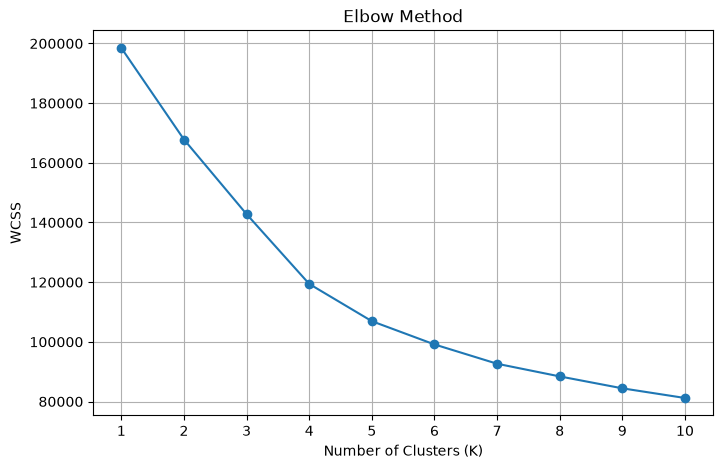

In [6]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [7]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("Cluster Labels:")
print(df['Cluster'].head(10))

print("\nNumber of Data Points in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

Cluster Labels:
0    2
1    0
2    1
3    1
4    2
5    1
6    0
7    0
8    0
9    1
Name: Cluster, dtype: int32

Number of Data Points in Each Cluster:
Cluster
0    13723
1    12737
2     1068
Name: count, dtype: int64


In [8]:
score = silhouette_score(
    X_scaled,
    df['Cluster'],
    sample_size=3000,
    random_state=42
)

print("Silhouette Score:", score)

Silhouette Score: 0.15723843782034044


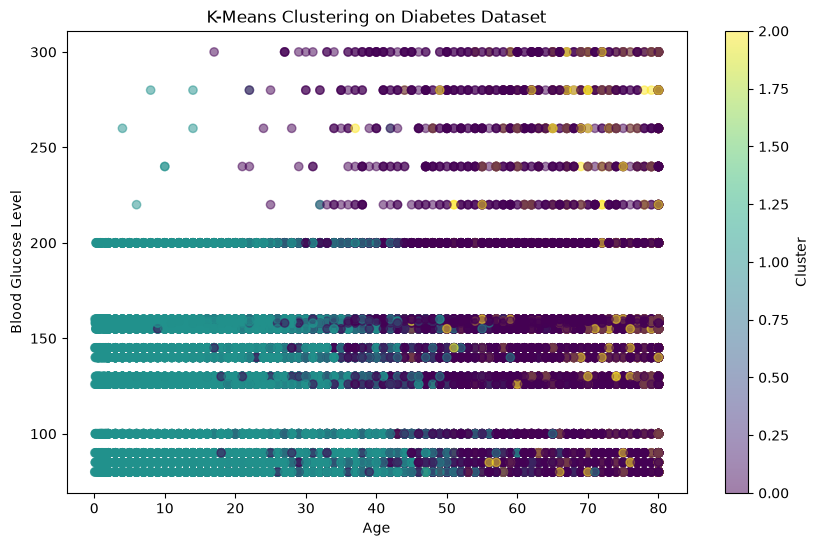

In [9]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['age'],
    df['blood_glucose_level'],
    c=df['Cluster'],
    cmap='viridis',
    alpha=0.5
)

plt.title('K-Means Clustering on Diabetes Dataset')
plt.xlabel('Age')
plt.ylabel('Blood Glucose Level')
plt.colorbar(label='Cluster')

plt.show()

In [10]:
print("Cluster Analysis:")
print(df.groupby('Cluster').mean(numeric_only=True))

Cluster Analysis:
               age  hypertension  heart_disease        bmi  HbA1c_level  \
Cluster                                                                   
0        57.084530      0.137579            0.0  30.493265     5.736552   
1        23.570514      0.000314            0.0  23.854849     5.264372   
2        68.110487      0.218165            1.0  29.156180     5.899906   

         blood_glucose_level  diabetes  
Cluster                                 
0                 145.632660  0.142680  
1                 128.538353  0.004318  
2                 153.250936  0.324906  


In [11]:
print("Cluster vs Diabetes Distribution:")
print(pd.crosstab(df['Cluster'], df['diabetes']))

Cluster vs Diabetes Distribution:
diabetes      0     1
Cluster              
0         11765  1958
1         12682    55
2           721   347


## Conclusion:

The K-Means clustering algorithm was successfully implemented on the diabetes prediction dataset. The dataset was preprocessed using StandardScaler and OneHotEncoder. The Elbow Method was used to determine the suitable number of clusters. The K-Means algorithm grouped the dataset into three clusters based on similarities in the input features. The clustering performance was evaluated using the Silhouette Score and visualized using a scatter plot. Cluster analysis was also performed to understand the characteristics of each group.